<a href="https://colab.research.google.com/github/OnkarM99/ML-colab/blob/main/1.%20NB_SVM%20Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [10]:
path = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

In [11]:
headernames = ['sepal-length', 'sepal-width', 'petal-length', 'petal-width', 'Class']

In [12]:
data = pd.read_csv(path, names=headernames)
data.shape

(150, 5)

In [13]:
data.head()

,sepal-length,sepal-width,petal-length,petal-width,Class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [14]:
X = data.iloc[:, :-1].values #take all rows as X variable except Class column at end
y = data.iloc[:, 4].values #take all rows & column at index position 4 i.e y column only

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30)

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train) #calculate mean and std deviation
X_train = scaler.transform(X_train) #normalisation step (X'=X-mean/std. deviation)
X_test = scaler.transform(X_test)

In [17]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train);

In [18]:
y_pred = classifier.predict(X_train)
accuracy = accuracy_score(y_train, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9523809523809523


In [19]:
y_pred = classifier.predict(X_test)

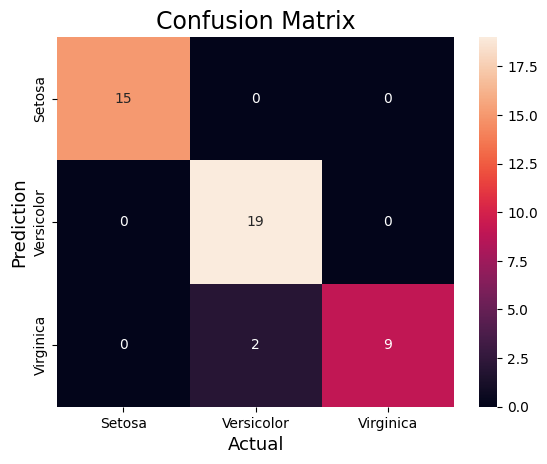

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
result = confusion_matrix(y_test, y_pred)
sns.heatmap(result, annot=True, fmt='g', xticklabels=['Setosa','Versicolor', 'Virginica'], yticklabels=['Setosa','Versicolor', 'Virginica'])
plt.ylabel('Prediction',fontsize=13)
plt.xlabel('Actual',fontsize=13)
plt.title('Confusion Matrix',fontsize=17)
plt.show()

In [21]:
result1 = classification_report(y_test, y_pred)
print("Classification Report:",)
print (result1)
result2 = accuracy_score(y_test,y_pred)
print("Accuracy:",result2)

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.90      1.00      0.95        19
 Iris-virginica       1.00      0.82      0.90        11

       accuracy                           0.96        45
      macro avg       0.97      0.94      0.95        45
   weighted avg       0.96      0.96      0.95        45

Accuracy: 0.9555555555555556


In [22]:
from sklearn.svm import SVC
accuracy_list = []
for i in ['linear', 'poly', 'rbf', 'sigmoid']:
  clf = SVC(kernel=i)
  clf.fit(X_train, y_train)
  y_pred = clf.predict(X_train)
  accuracy = accuracy_score(y_train, y_pred)
  accuracy_list.append(accuracy)
  print("accuracy of "+ i, "is", float(accuracy))

accuracy of linear is 0.9619047619047619
accuracy of poly is 0.9142857142857143
accuracy of rbf is 0.9714285714285714
accuracy of sigmoid is 0.9238095238095239


(0.8, 1.0)

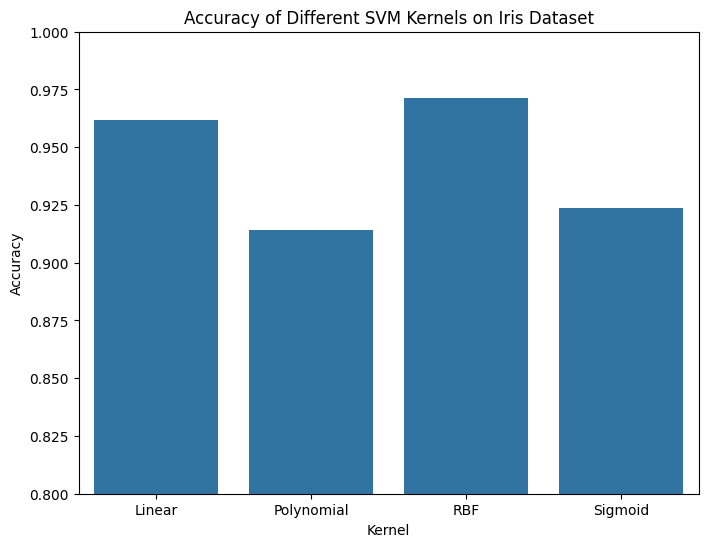

In [23]:
accuracies = { 'Linear': accuracy_list[0], 'Polynomial': accuracy_list[1], 'RBF': accuracy_list[2], 'Sigmoid': accuracy_list[3]}
plt.figure(figsize=(8, 6))
sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()))
plt.xlabel('Kernel')
plt.ylabel('Accuracy')
plt.title('Accuracy of Different SVM Kernels on Iris Dataset')
plt.ylim(0.8, 1.0) # Set y-axis limits for better visualizationplt.show()